In [1]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import hgm
# noinspection PyUnresolvedReferences
from models import bom

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/utils/train_utils.py'>

In [3]:
selection_n = ['DD01', 'VB02', 'AVAR', 'ALA']  # 'DB01',
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

read_ids = list(range(0, 33+1))
# read_ids = [0, 12, 14, 23, 29, 32]
# read_ids = [14]
plot_id = 14

dims = 1
dims_preca = 5

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])

In [5]:
# reduce

(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces_gcamp,
																	[ds for ds in discrete_states_gcamp],
																	n_cv=dims, n_pc=dims_preca)

modes_gcamp = modes_manifold
traces_reconstructed_gcamp = recos_manifold
traces_residual_gcamp = [trace - trace_man for trace, trace_man in zip(traces_gcamp, traces_reconstructed_gcamp)]

In [6]:
# plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] eigenworms',
# 					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
# 					   eigenworms_gcamp[file_ids_gcamp.index(plot_id)],
# 					   plots_per_row=1, ylimits=None)

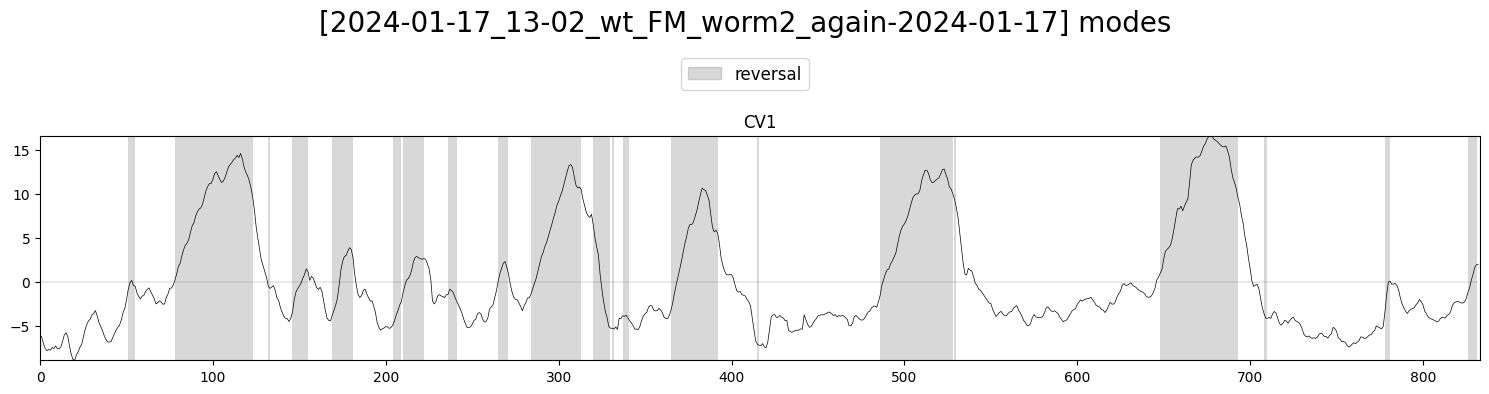

In [7]:
plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] modes',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
					   modes_gcamp[file_ids_gcamp.index(plot_id)],
					   plots_per_row=1, ylimits=None)

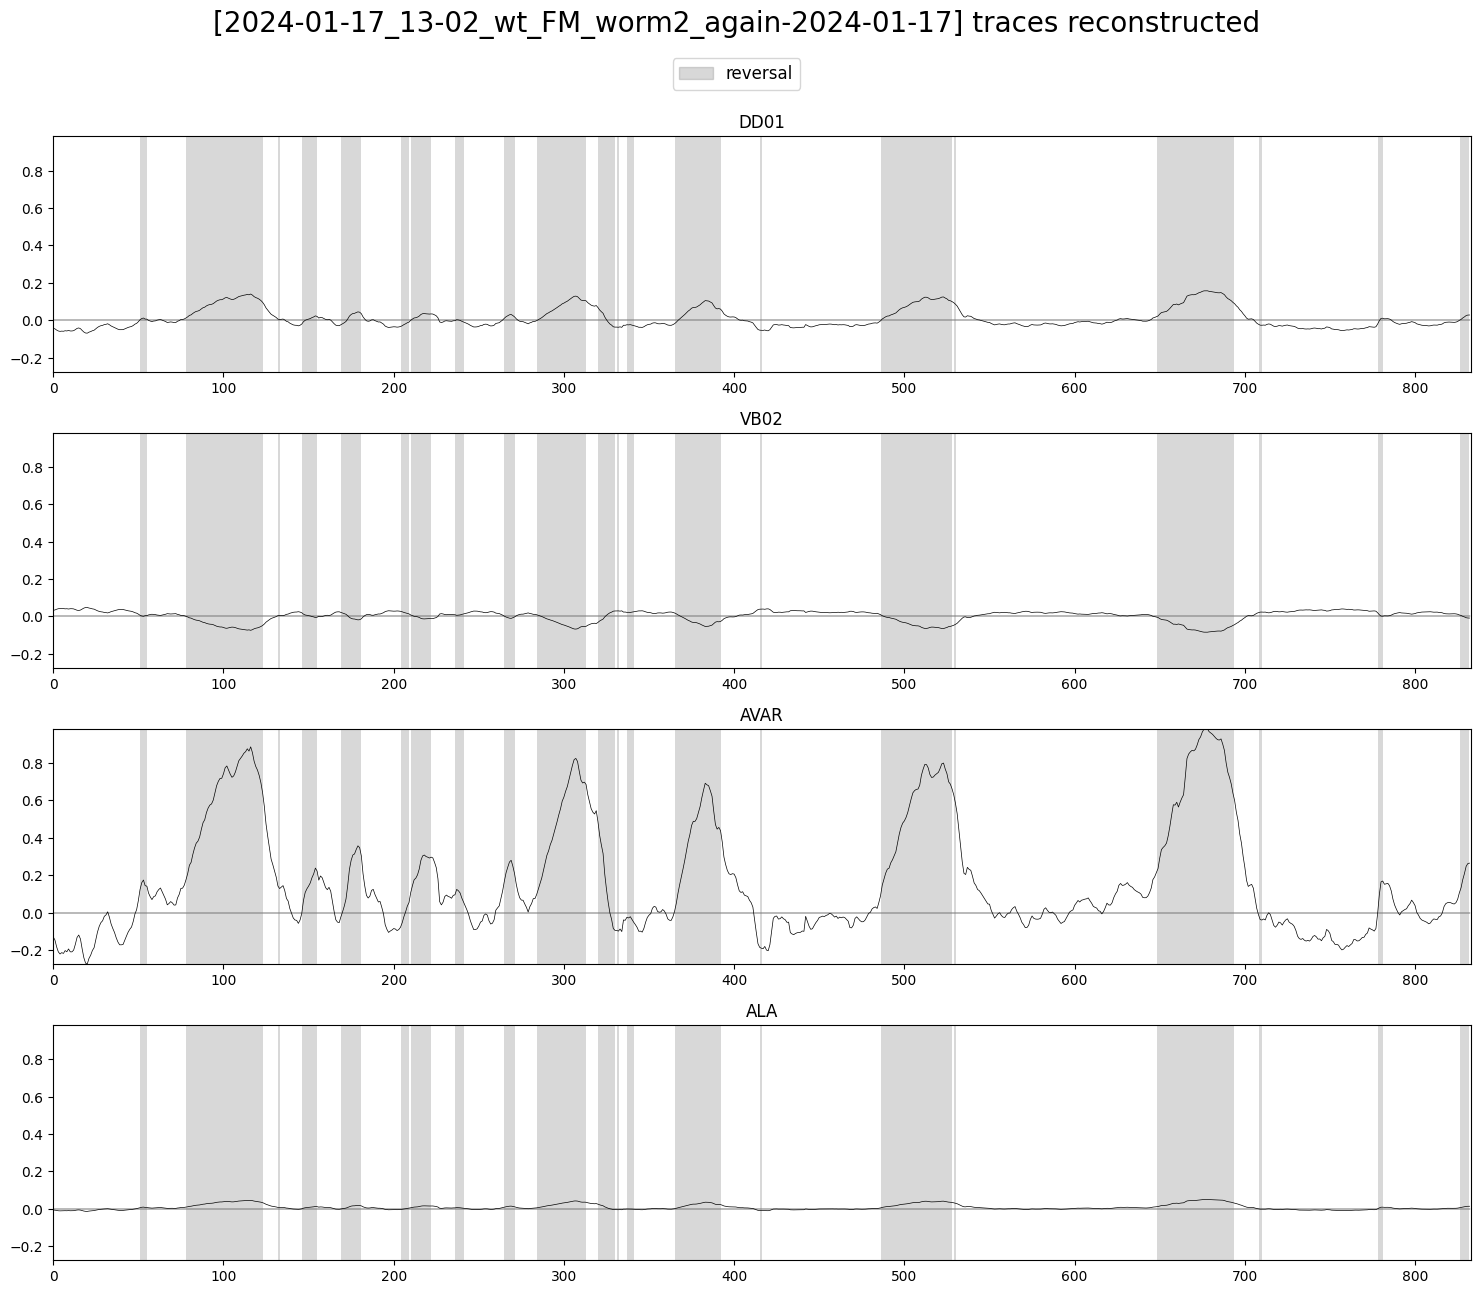

In [8]:
plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] traces reconstructed',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_reconstructed_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

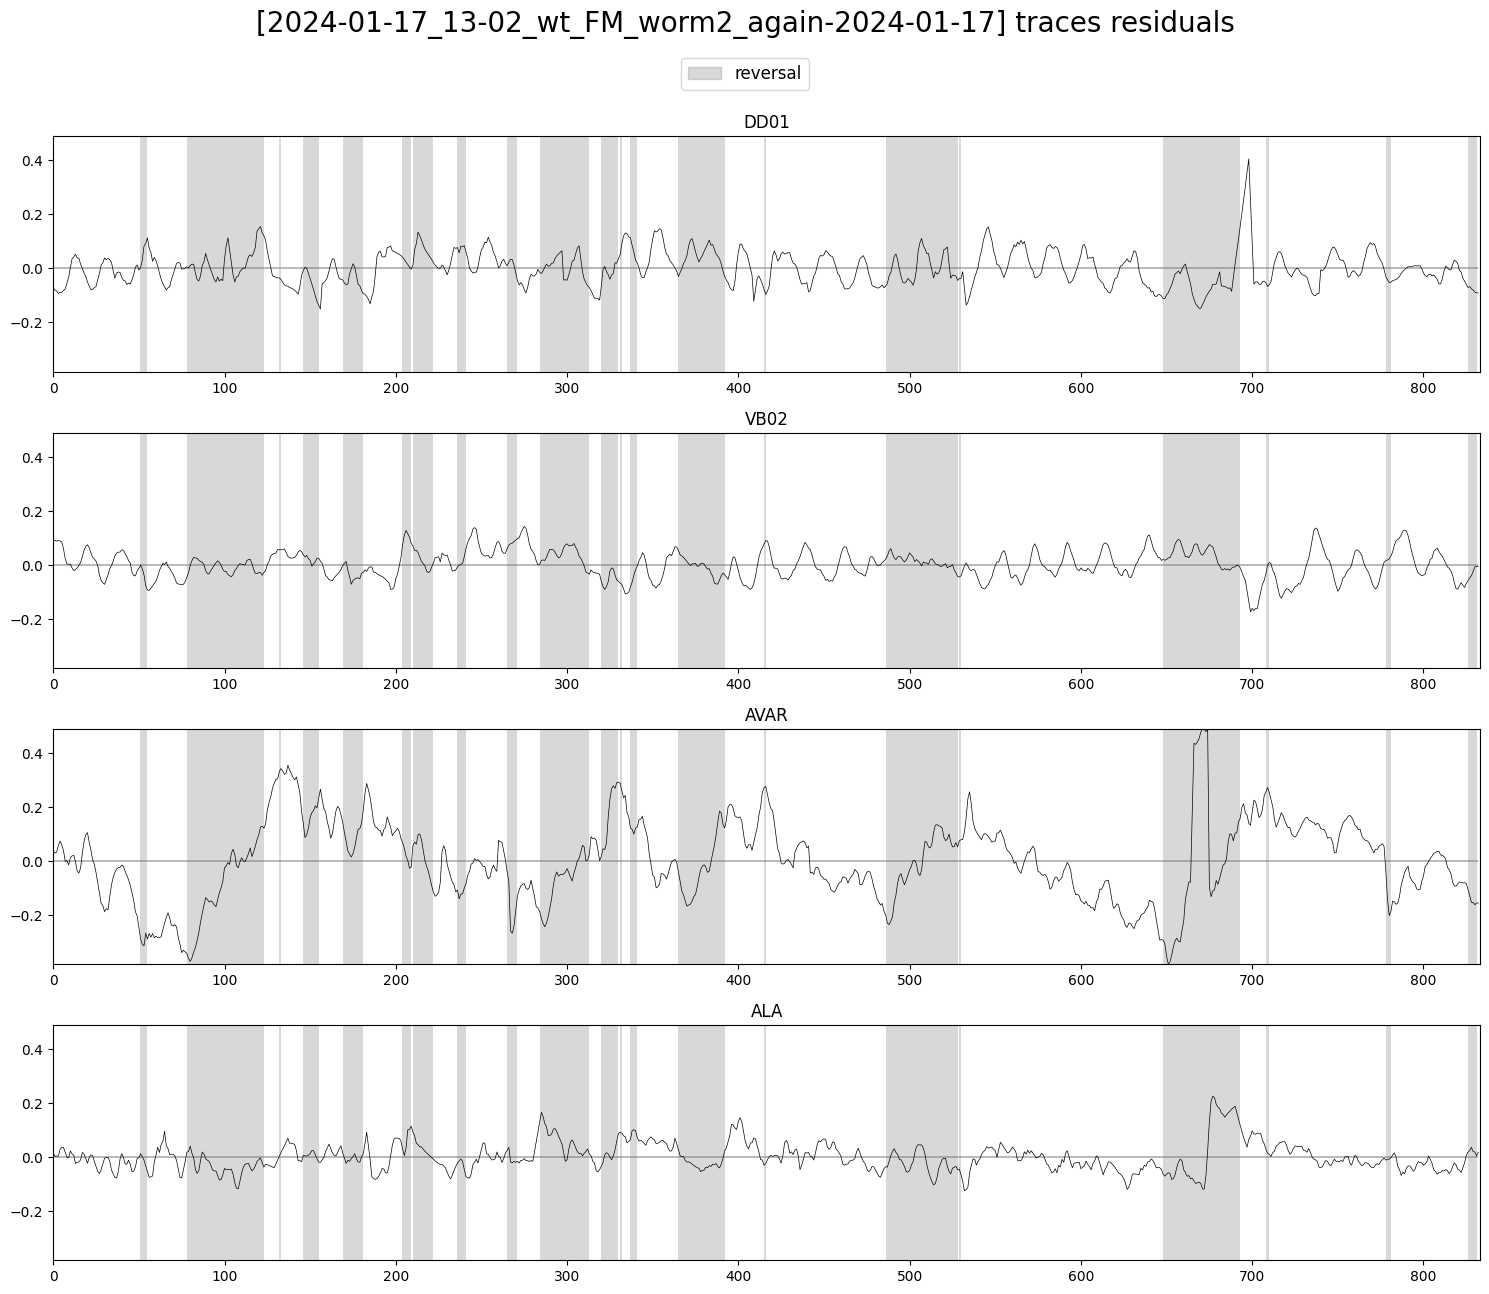

In [9]:
plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] traces residuals',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_residual_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)

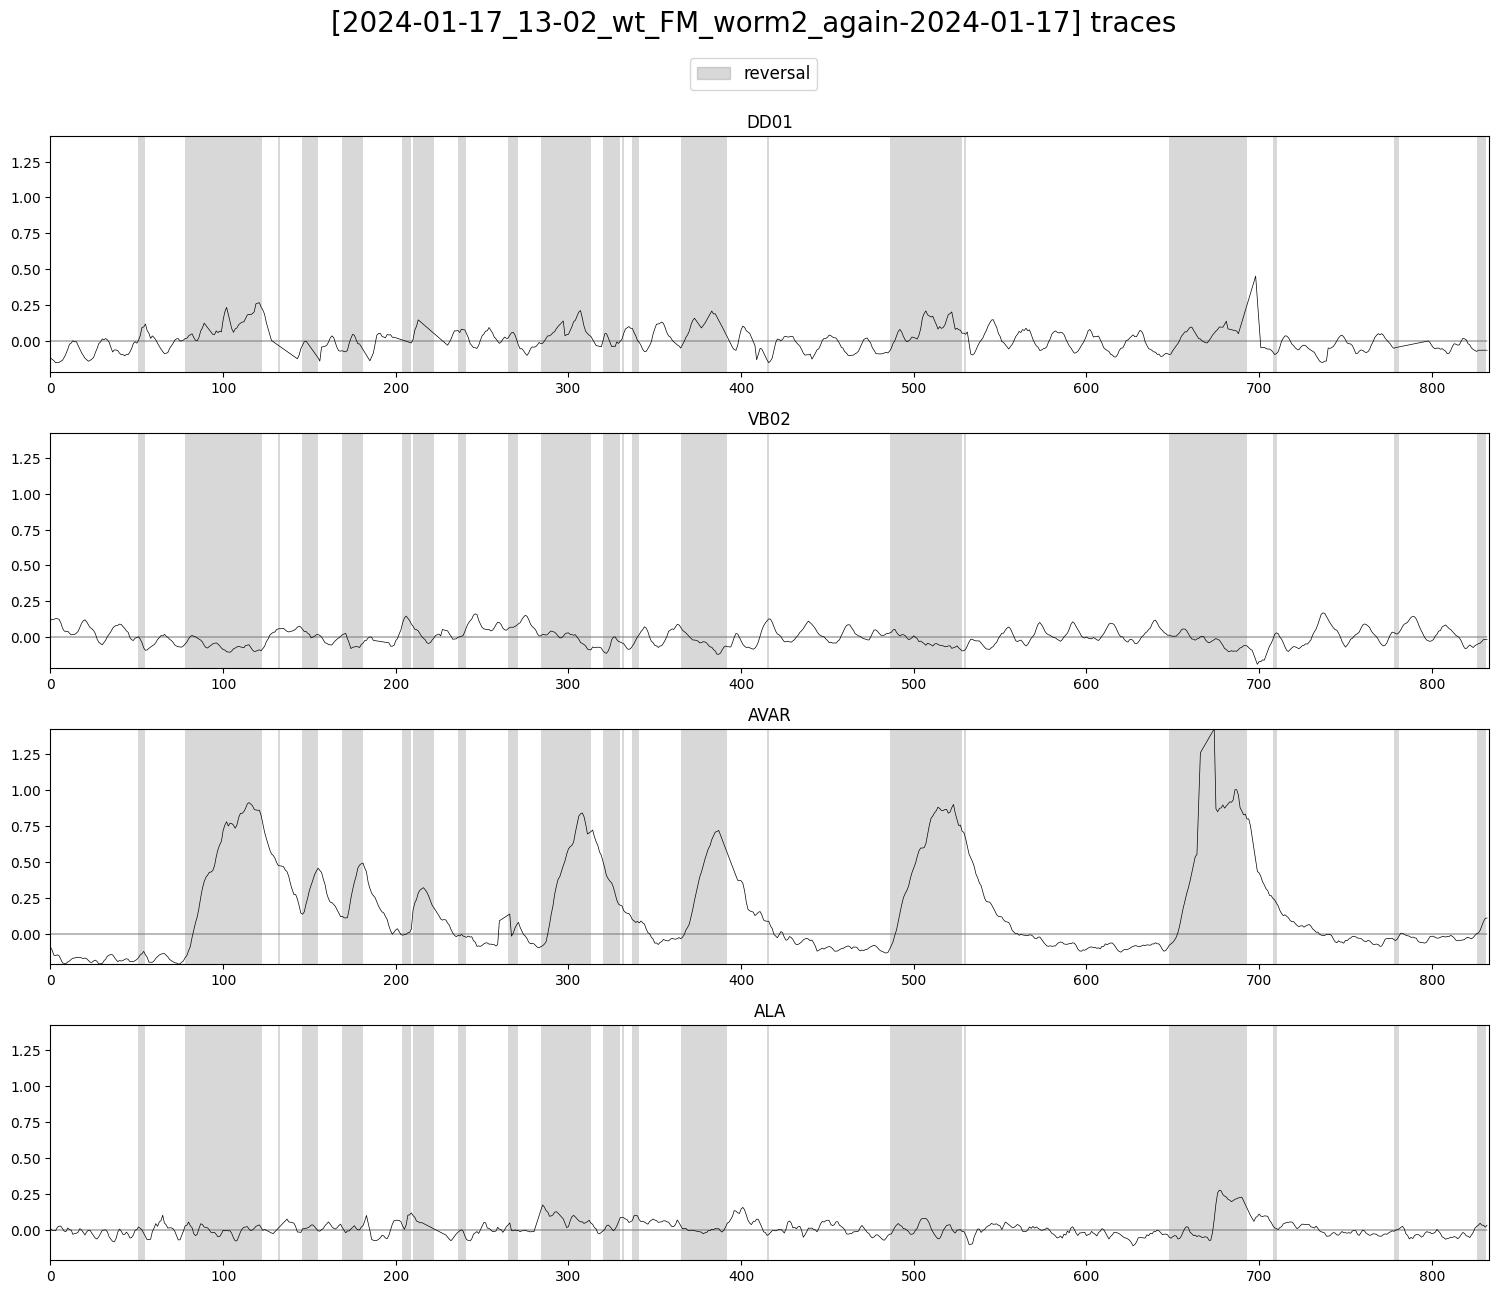

In [10]:
plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] traces',
					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)][['REV']],
					   traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
					   plots_per_row=1, ylimits=None)